In [1]:
import numpy as np
import pandas as pd

input_file = "winequality-red.csv"
df = pd.read_csv(input_file)
df.shape

(1599, 12)

In [2]:
def make_features(df):
    X = df.drop(["quality"], axis=1).copy()
    X["so2_ratio"] = X["free sulfur dioxide"] / X["total sulfur dioxide"]
    X["alc_sulph"] = X["alcohol"] * X["sulphates"]
    X["alc_va"] = X["alcohol"] / X["volatile acidity"]
    X["log_sulph"] = np.log(X["sulphates"])
    X["log_chl"] = np.log(X["chlorides"])
    X["log_tso2"] = np.log(X["total sulfur dioxide"])
    X["acid_total"] = X["fixed acidity"] + X["volatile acidity"] + X["citric acid"]
    return X

wine_base = df.drop(["quality"], axis=1)
wine_prepared = make_features(df)
wine_labels = df["quality"].copy()
wine_prepared.shape

(1599, 18)

In [3]:
def display_scores(scores):
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

In [4]:
# 1) 모델 비교: 원본 특성 vs 내 특성, 여러 회귀 모델 (10-fold RMSE, shuffle=True)
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

kf = KFold(n_splits=10, shuffle=True, random_state=42)
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)

def rmse_cv(model, X):
    return np.sqrt(-cross_val_score(model, X, wine_labels, scoring="neg_mean_squared_error", cv=kf, n_jobs=-1)).mean()

models = {
    "LinearRegression": LinearRegression(),
    "SGD": make_pipeline(StandardScaler(), SGDRegressor(random_state=42)),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "XGB": XGBRegressor(n_estimators=800, learning_rate=0.02, max_depth=6, subsample=0.8, colsample_bytree=0.5, n_jobs=1),
}
for name, model in models.items():
    print(f"{name:18s} 원본 {rmse_cv(model, wine_base):.4f}   내 특성 {rmse_cv(model, wine_prepared):.4f}")

LinearRegression   원본 0.6509   내 특성 0.6367
SGD                원본 0.6504   내 특성 0.6421


SVR                원본 0.6186   내 특성 0.6180
DecisionTree       원본 0.6849   내 특성 0.6827


RandomForest       원본 0.5644   내 특성 0.5688


ExtraTrees         원본 0.5504   내 특성 0.5499


GradientBoosting   원본 0.6136   내 특성 0.6101


XGB                원본 0.5586   내 특성 0.5555


In [5]:
# 2) 하이퍼파라미터 탐색 (Grid Search, 10-fold shuffle=True): 가장 좋은 ExtraTrees 와 XGB
from sklearn.model_selection import GridSearchCV

et_search = GridSearchCV(ExtraTreesRegressor(n_estimators=1000, random_state=42),
                         {"max_features": [0.25, 0.4, 0.6, 1.0], "min_samples_leaf": [1, 2]},
                         cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
et_search.fit(wine_prepared, wine_labels)
print("ET ", et_search.best_params_, np.sqrt(-et_search.best_score_))

xgb_search = GridSearchCV(XGBRegressor(n_estimators=1500, learning_rate=0.01, subsample=0.8, colsample_bytree=0.5, n_jobs=1),
                          {"max_depth": [4, 6, 8]},
                          cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
xgb_search.fit(wine_prepared, wine_labels)
print("XGB", xgb_search.best_params_, np.sqrt(-xgb_search.best_score_))

ET  {'max_features': 0.25, 'min_samples_leaf': 1} 0.5457672584617046


XGB {'max_depth': 8} 0.5521987719375718


In [6]:
# 3) 최종 모델: 튜닝한 ExtraTrees·XGB + RandomForest + SVR 을 Stacking (최종 판정기 LinearRegression, 양수 가중치)
from sklearn.ensemble import StackingRegressor

final_reg = StackingRegressor(
    estimators=[("et", et_search.best_estimator_),
                ("xgb", xgb_search.best_estimator_),
                ("rf", RandomForestRegressor(n_estimators=1000, max_features=0.33, random_state=42)),
                ("svr", make_pipeline(StandardScaler(), SVR(C=1, gamma=0.03, epsilon=0.3)))],
    final_estimator=LinearRegression(positive=True),
    cv=kf5)

In [7]:
final_scores = cross_val_score(final_reg, wine_prepared, wine_labels, scoring="neg_mean_squared_error", cv=kf, n_jobs=-1)
final_rmse_scores = np.sqrt(-final_scores)
display_scores(final_rmse_scores)

/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Scores: [0.5311541  0.50891134 0.57043499 0.5413296  0.56348    0.58480758
 0.52120871 0.58960486 0.50697302 0.51096007]
Mean: 0.542886426522692
Standard deviation: 0.030325532743801117


In [8]:
np.mean(final_rmse_scores)

np.float64(0.542886426522692)

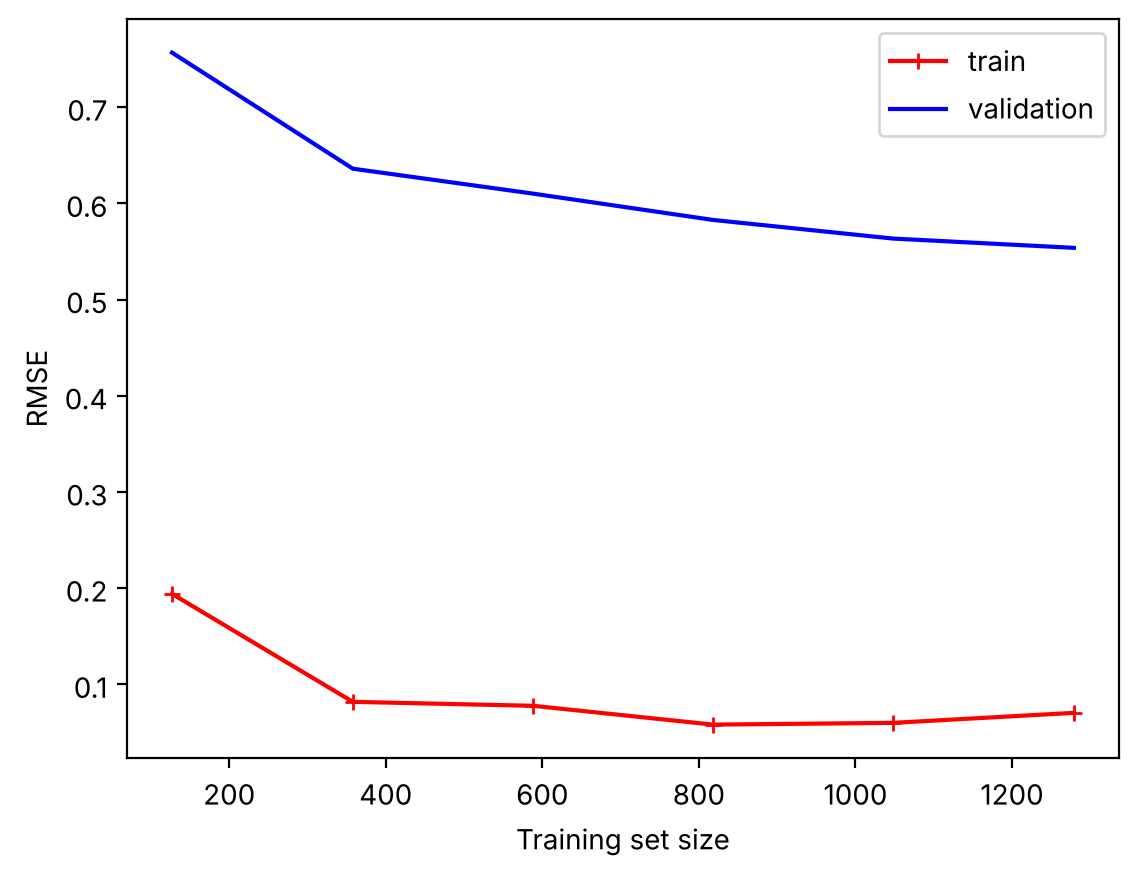

In [9]:
# 학습 곡선: 학습 데이터 양에 따른 학습/검증 RMSE
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(final_reg, wine_prepared, wine_labels, cv=kf5, scoring="neg_mean_squared_error",
                                         train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.plot(sizes, np.sqrt(-train_sc.mean(axis=1)), "r-+", label="train")
plt.plot(sizes, np.sqrt(-val_sc.mean(axis=1)), "b-", label="validation")
plt.xlabel("Training set size"); plt.ylabel("RMSE"); plt.legend(); plt.show()